<a href="https://colab.research.google.com/github/gauravshukla73074-cloud/COLLEGE_CLUB/blob/main/FitMirror_VTON_Test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Fri Oct 16 19:08:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    memory = torch.cuda.get_device_properties(0).total_memory
    print("GPU memory:", round(memory / (1024**3), 2), "GB")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
!git clone https://github.com/fashn-AI/fashn-vton-1.5.git

Cloning into 'fashn-vton-1.5'...
remote: Enumerating objects: 92, done.
remote: Counting objects: 100% (25/25), done.
remote: Compressing objects: 100% (12/12), done.
remote: Total 92 (delta 20), reused 13 (delta 13), pack-reused 67 (from 1)
Receiving objects: 100% (92/92), 334.44 KiB | 37.16 MiB/s, done.
Resolving deltas: 100% (29/29), done.


In [4]:
%cd /content/fashn-vton-1.5

/content/fashn-vton-1.5


In [5]:
!ls -la

total 56
drwxr-xr-x 7 root root  4096 Oct 16 19:13 .
drwxr-xr-x 1 root root  4096 Oct 16 19:13 ..
drwxr-xr-x 3 root root  4096 Oct 16 19:13 examples
drwxr-xr-x 8 root root  4096 Oct 16 19:13 .git
-rw-r--r-- 1 root root   978 Oct 16 19:13 .gitignore
-rw-r--r-- 1 root root 10835 Oct 16 19:13 LICENSE
-rw-r--r-- 1 root root  1864 Oct 16 19:13 pyproject.toml
-rw-r--r-- 1 root root  4747 Oct 16 19:13 README.md
drwxr-xr-x 2 root root  4096 Oct 16 19:13 scripts
drwxr-xr-x 3 root root  4096 Oct 16 19:13 src
drwxr-xr-x 2 root root  4096 Oct 16 19:13 tests


In [6]:
!cat README.md

# FASHN VTON v1.5: Efficient Maskless Virtual Try-On in Pixel Space

<div align="center">
  <a href="https://fashn.ai/research/vton-1-5"><img src='https://img.shields.io/badge/Project-Page-1A1A1A?style=flat' alt='Project Page'></a>&ensp;
  <a href='https://huggingface.co/fashn-ai/fashn-vton-1.5'><img src='https://img.shields.io/badge/Hugging%20Face-Model-FFD21E?style=flat&logo=HuggingFace&logoColor=FFD21E' alt='Hugging Face Model'></a>&ensp;
  <a href="https://huggingface.co/spaces/fashn-ai/fashn-vton-1.5"><img src='https://img.shields.io/badge/Hugging%20Face-Spaces-FFD21E?style=flat&logo=HuggingFace&logoColor=FFD21E' alt='Hugging Face Spaces'></a>&ensp;
  <a href=""><img src='https://img.shields.io/badge/arXiv-Coming%20Soon-b31b1b?style=flat&logo=arXiv&logoColor=b31b1b' alt='arXiv'></a>&ensp;
  <a href="LICENSE"><img src='https://img.shields.io/badge/License-Apache--2.0-gray?style=flat' alt='License'></a>
</div>

by [FASHN AI](https://fashn.ai)

Virtual try-on model that generates pho

In [7]:
!cat pyproject.toml

[build-system]
requires = ["setuptools>=61.0", "wheel"]
build-backend = "setuptools.build_meta"

[project]
name = "fashn-vton"
version = "1.5.0"
description = "FASHN VTON v1.5"
license = {text = "Apache-2.0"}
authors = [
    {name = "FASHN AI", email = "dan@fashn.ai"}
]
keywords = ["virtual try-on", "diffusion models", "fashion", "AI", "deep learning"]
classifiers = [
    "Development Status :: 4 - Beta",
    "Intended Audience :: Developers",
    "Intended Audience :: Science/Research",
    "License :: OSI Approved :: Apache Software License",
    "Operating System :: OS Independent",
    "Programming Language :: Python :: 3",
    "Programming Language :: Python :: 3.10",
    "Programming Language :: Python :: 3.11",
    "Programming Language :: Python :: 3.12",
    "Topic :: Scientific/Engineering :: Artificial Intelligence",
    "Topic :: Scientific/Engineering :: Image Processing",
]
requires-python = ">=3.10"
dependencies = [
    "torch>=2.0.0",
    "torchvision>=0.15.0",
    "saf

In [8]:
!ls -lah scripts/


total 24K
drwxr-xr-x 2 root root 4.0K Oct 16 19:13 .
drwxr-xr-x 7 root root 4.0K Oct 16 19:13 ..
-rw-r--r-- 1 root root  12K Oct 16 19:13 debug_masks.py
-rw-r--r-- 1 root root 3.0K Oct 16 19:13 download_weights.py


In [9]:
!find examples -maxdepth 3 -type f

examples/basic_inference.py
examples/data/model.webp
examples/data/garment.webp


In [10]:
%cd /content/fashn-vton-1.5

!pip install -e .

/content/fashn-vton-1.5
Obtaining file:///content/fashn-vton-1.5
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.6/255.6 MB 4.9 MB/s eta 0:00:00
  Building editable for fashn-vton (pyproject.toml) ... done
  Created wheel for fashn-vton: filename=fashn_vton-1.5.0-0.editable-py3-none-any.whl size=5771 sha256=0bc07daeee2c1c6ff45d64054f04d9fe5aa5b435cf2167786d55ef12d7b05990
  Stored in directory: /tmp/pip-ephem-wheel-cache-_asg3v_6/wheels/81/c7/ee/834de7859c1823447a7c5e12688cc45e439f96b49e9fa887ca
Successfully built fashn-vton


In [11]:
%cd /content/fashn-vton-1.5

!python scripts/download_weights.py --weights-dir ./weights

/content/fashn-vton-1.5



model.safetensors: downloading bytes:   0% 5.56M/1.94G [00:01<10:37, 3.04MB/s]
model.safetensors: downloading bytes:   1% 22.8M/1.94G [00:02<01:58, 16.2MB/s, 1.38MB/s  ]
model.safetensors: downloading bytes:  10% 204M/1.94G [00:04<00:18, 94.7MB/s, 16.3MB/s  ]
model.safetensors: downloading bytes:  12% 227M/1.94G [00:04<00:16, 103MB/s, 17.8MB/s  ] 
model.safetensors: downloading bytes:  12% 243M/1.94G [00:04<00:14, 114MB/s, 18.9MB/s  ]
model.safetensors: downloading bytes:  13% 255M/1.94G [00:04<00:14, 115MB/s, 20.1MB/s  ]
model.safetensors: downloading bytes:  14% 270M/1.94G [00:04<00:13, 122MB/s, 21.0MB/s  ]
model.safetensors: downloading bytes:  16% 304M/1.94G [00:04<00:11, 148MB/s, 23.1MB/s  ]
model.safetensors: downloading bytes:  55% 1.07G/1.94G [00:09<00:03, 223MB/s, 71.3MB/s  ]
model.safetensors: downloading bytes:  56% 1.09G/1.94G [00:09<00:03, 237MB/s, 72.7MB/s  ]
model.safetensors: downloading bytes:  58% 1.13G/1.94G [00:09<00:03, 218MB/s, 75.5MB/s 

In [12]:
!ls -lh /content/fashn-vton-1.5/weights/

total 1.9G
drwxr-xr-x 3 root root 4.0K Oct 16 19:25 dwpose
-rw-r--r-- 1 root root 1.9G Oct 16 19:25 model.safetensors


In [13]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [14]:
%cd /content/fashn-vton-1.5

!python examples/basic_inference.py \
    --weights-dir ./weights \
    --person-image examples/data/model.webp \
    --garment-image examples/data/garment.webp \
    --category tops

/content/fashn-vton-1.5
Loading images...
Loading pipeline from ./weights...
TryOnPipeline - INFO - Using device: cuda
TryOnPipeline - INFO - Using dtype: torch.bfloat16
TryOnPipeline - INFO - Loading TryOnModel from /content/fashn-vton-1.5/weights/model.safetensors
TryOnPipeline - INFO - TryOnModel loaded
TryOnPipeline - INFO - Loading DWPose from /content/fashn-vton-1.5/weights/dwpose
2026-10-16 19:28:07.463987487 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:856 operator()] No registered plugin EP device found for 'CUDAExecutionProvider' with device_id=0
2026-10-16 19:28:09.153080578 [W:onnxruntime:Default, onnxruntime_pybind_state.cc:856 operator()] No registered plugin EP device found for 'CUDAExecutionProvider' with device_id=0
2026-10-16 19:28:09.202432074 [W:onnxruntime:, session_state.cc:1598 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly as

Image size: (576, 864)


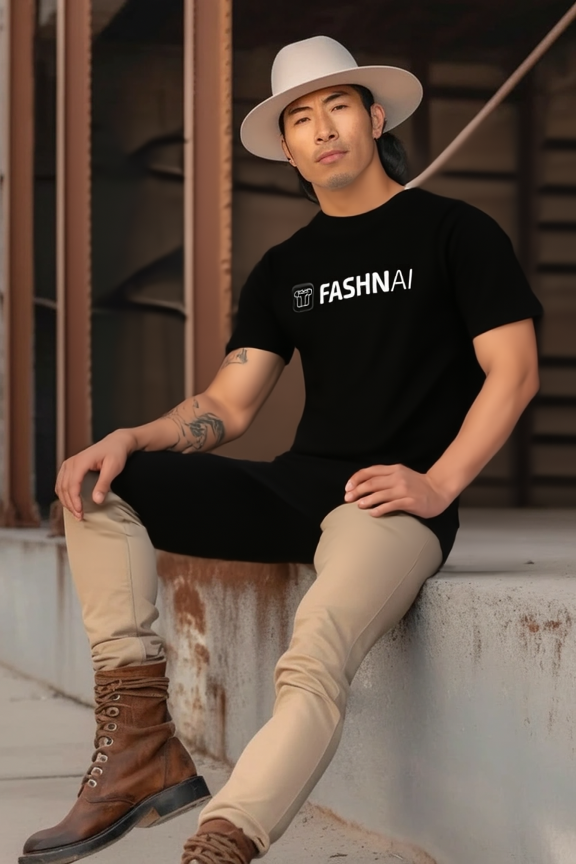

In [15]:
from PIL import Image
from IPython.display import display

image_path = "/content/fashn-vton-1.5/outputs/output_00.png"

result = Image.open(image_path)

print("Image size:", result.size)

display(result)

In [31]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving Screenshot 2025-10-15 155651.png to Screenshot 2025-10-15 155651.png
Saving Screenshot (39).png to Screenshot (39) (4).png
Uploaded files: ['Screenshot 2025-10-15 155651.png', 'Screenshot (39) (4).png']


In [32]:
import os

for filename in uploaded.keys():
    print(filename, "->", os.path.exists(filename))

Screenshot 2025-10-15 155651.png -> True
Screenshot (39) (4).png -> True


In [34]:
import os

for root, dirs, files in os.walk("/content"):
    for filename in files:
        if filename in [
            "Screenshot 2025-10-15 155651.png",
            "Screenshot (39) (4).png"
        ]:
            print(os.path.join(root, filename))

/content/fashn-vton-1.5/Screenshot 2025-10-15 155651.png
/content/fashn-vton-1.5/Screenshot (39) (4).png


Person image:


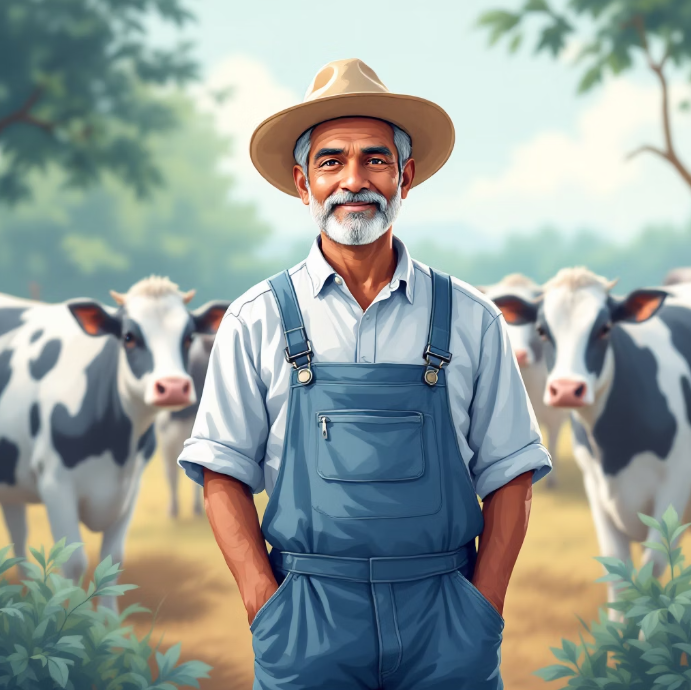

Garment image:


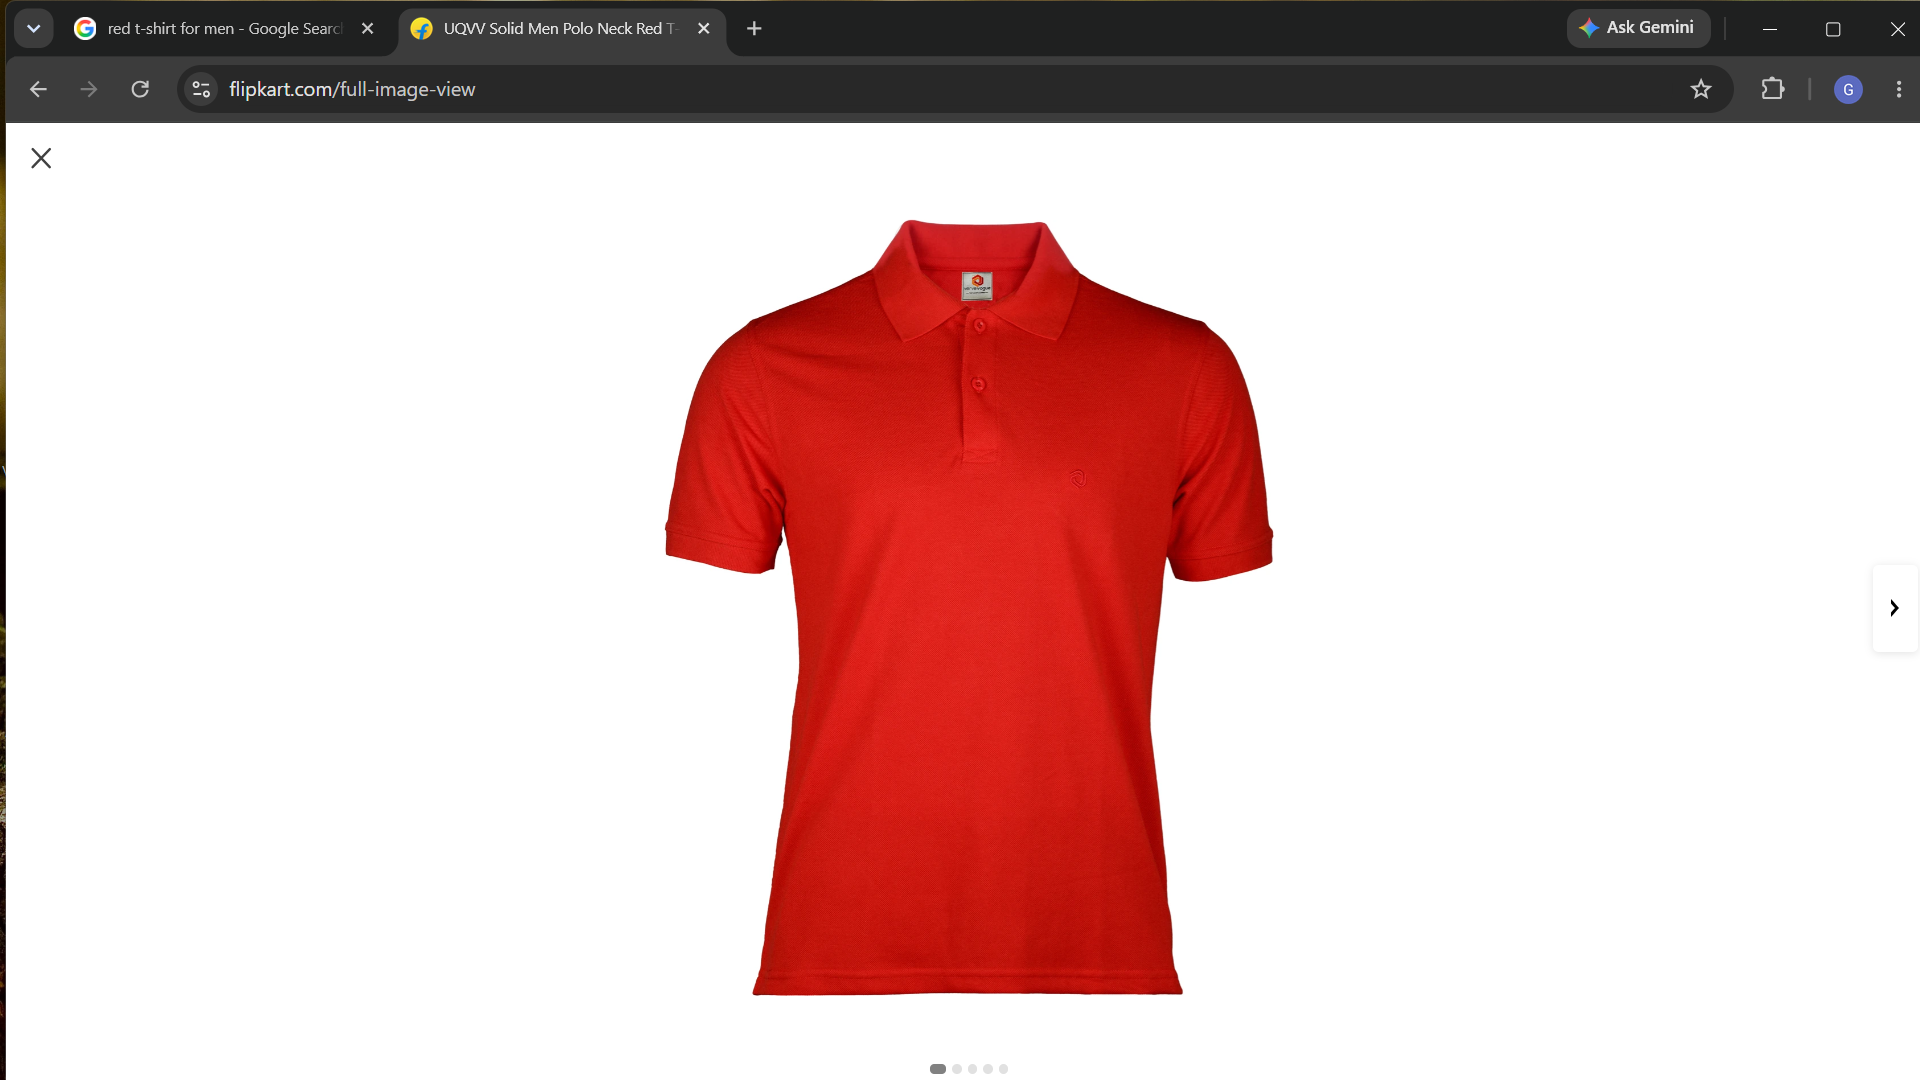

In [35]:
from PIL import Image
from IPython.display import display

person_path = "/content/fashn-vton-1.5/Screenshot 2025-10-15 155651.png"
garment_path = "/content/fashn-vton-1.5/Screenshot (39) (4).png"

person = Image.open(person_path).convert("RGB")
garment = Image.open(garment_path).convert("RGB")

print("Person image:")
display(person)

print("Garment image:")
display(garment)

TryOnPipeline - INFO - Running inference with 30 timesteps...


Sampling:   0%|          | 0/30 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


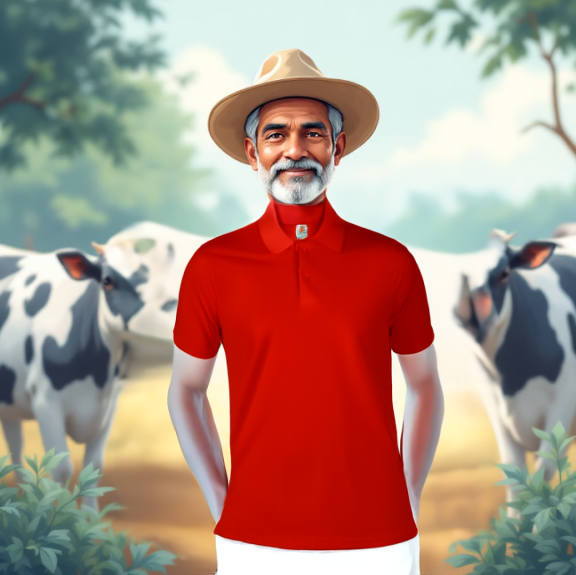

In [36]:
result = pipeline(
    person_image=person,
    garment_image=garment,
    category="tops"
)

display(result.images[0])

In [37]:
from google.colab import files

uploaded = files.upload()
print("Uploaded files:", list(uploaded.keys()))

Saving Screenshot 2026-10-17 015857.png to Screenshot 2026-10-17 015857.png
Saving Screenshot 2026-10-17 015600.png to Screenshot 2026-10-17 015600.png
Uploaded files: ['Screenshot 2026-10-17 015857.png', 'Screenshot 2026-10-17 015600.png']


In [38]:
import os

for root, dirs, filenames in os.walk("/content"):
    for filename in filenames:
        if filename in [
            "Screenshot 2026-10-17 015857.png",
            "Screenshot 2026-10-17 015600.png"
        ]:
            print(os.path.join(root, filename))

/content/fashn-vton-1.5/Screenshot 2026-10-17 015600.png
/content/fashn-vton-1.5/Screenshot 2026-10-17 015857.png


Image 1:


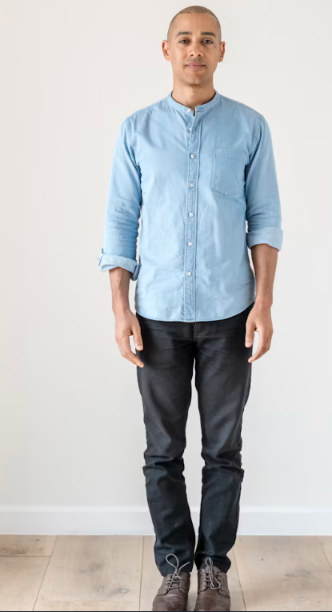

Image 2:


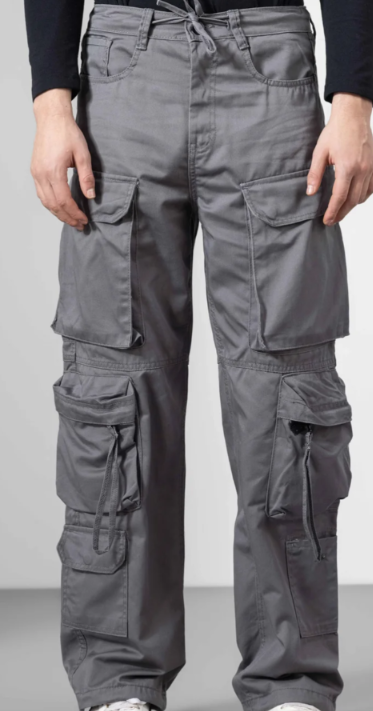

In [39]:
from PIL import Image
from IPython.display import display

image1_path = "/content/fashn-vton-1.5/Screenshot 2026-10-17 015600.png"
image2_path = "/content/fashn-vton-1.5/Screenshot 2026-10-17 015857.png"

print("Image 1:")
display(Image.open(image1_path))

print("Image 2:")
display(Image.open(image2_path))

In [40]:
person_path = image1_path
garment_path = image2_path

person = Image.open(person_path).convert("RGB")
garment = Image.open(garment_path).convert("RGB")

TryOnPipeline - INFO - Running inference with 30 timesteps...


Sampling:   0%|          | 0/30 [00:00<?, ?it/s]

TryOnPipeline - INFO - Generated 1 images


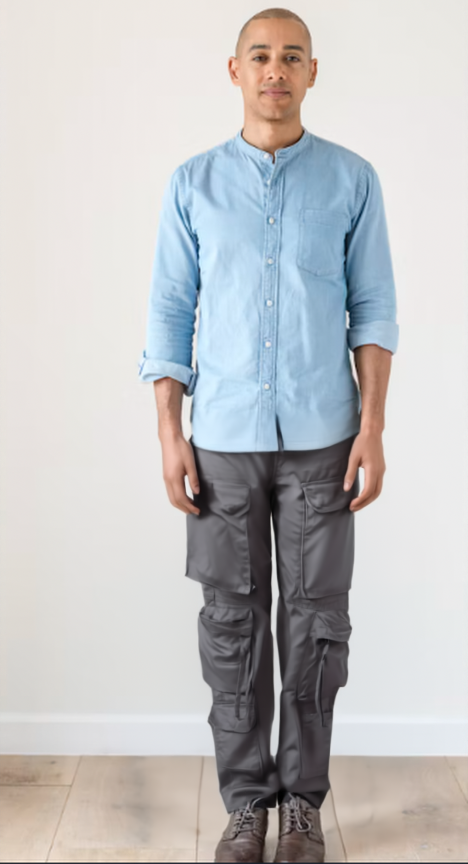

In [41]:
result = pipeline(
    person_image=person,
    garment_image=garment,
    category="bottoms"
)

display(result.images[0])